# 지하철 보정 2 — '문 하나 정류장' 다시 정의

기본 조건은 5개 버전 모두 같다: **멀리 가는 노선 ≤ 1 AND 월 승차 ≥ 서울 정류장 75퍼센타일**.
퍼센타일은 보정 전 원래 값(`13,482.5`)을 그대로 쓴다.

| 버전 | 지하철 보정 |
|---|---|
| `base` | 없음 (기존 `door1_main`) |
| `name` | 정류소명에 '○○역'이 들어간 정류장 제외 |
| `d200` | 가장 가까운 지하철역 200m 이내 제외 |
| `d300` | 300m 이내 제외 (**메인**) |
| `d500` | 500m 이내 제외 |

In [1]:
# 프로젝트 ROOT 찾아서 공통 경로·함수 불러오기 (경로 문자열은 src/paths.py에만)
import sys
from pathlib import Path

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "CLAUDE.md").exists())
sys.path.insert(0, str(ROOT / "src"))
from paths import RAW, EXT, PROC, REPORTS

print("ROOT:", ROOT)

ROOT: C:\study\aix\aix_2


In [2]:
import re
from pathlib import Path

import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

mpl.rcParams["font.family"] = "Malgun Gothic"
mpl.rcParams["axes.unicode_minus"] = False
sns.set_theme(style="whitegrid", font="Malgun Gothic", rc={"axes.unicode_minus": False})
pd.set_option("display.max_columns", 60)
pd.set_option("display.max_rows", 200)
pd.set_option("display.width", 230)

TARGET = "01278"          # 상명대정문

stop = pd.read_csv(PROC / "stop_metrics_subway.csv", encoding="utf-8-sig",
                   dtype={"버스정류장ARS번호": str, "1위노선": str})
print(stop.shape)

# 기본 조건 (퍼센타일은 보정 전 값 그대로)
P75 = stop["월승차"].quantile(0.75)
print(f"월승차 75퍼센타일 = {P75:,.1f}")
stop["기본조건"] = (stop["멀리가는노선수"] <= 1) & (stop["월승차"] >= P75)
print("기본조건 통과(= base):", int(stop["기본조건"].sum()))
print("기존 door1_main과 동일:", bool((stop["기본조건"] == stop["door1_main"]).all()))

(10615, 24)
월승차 75퍼센타일 = 13,482.5
기본조건 통과(= base): 354
기존 door1_main과 동일: True


## 1. 이름(A안) 규칙 점검

`r'역($|[.\s(]|\d+번)'` 로 "○○역"을 잡고, '역촌'·'역삼' 같은 동네 이름은 안 잡히는지 확인한다.

In [3]:
RE_STATION = re.compile(r"역(?:$|[.\s(]|\d+번)")
stop["이름에역"] = stop["정류장명"].fillna("").str.contains(RE_STATION)

# '역'이 들어간 이름만 모아서 매칭 결과 확인
has_yeok = stop[stop["정류장명"].fillna("").str.contains("역")]
print(f"이름에 '역' 글자가 있는 정류장: {len(has_yeok)}개 "
      f"/ 그중 규칙에 걸린 것: {int(has_yeok['이름에역'].sum())}개")

chk = (has_yeok[["정류장명", "이름에역"]].drop_duplicates("정류장명")
       .sort_values("정류장명").reset_index(drop=True))
print("\n[규칙에 걸린 예시 20개]")
print(chk[chk["이름에역"]].head(20).to_string(index=False))

이름에 '역' 글자가 있는 정류장: 1427개 / 그중 규칙에 걸린 것: 1201개

[규칙에 걸린 예시 20개]
               정류장명  이름에역
             1호선구일역  True
         2호선교대역7번출구  True
            3호선독립문역  True
           4호선성신여대역  True
        7호선가산디지털단지역  True
            7호선수락산역  True
7호선신대방삼거리역2번출구.국민은행  True
     7호선신대방삼거리역4번출구  True
   7호선장승배기역.상도2치안센터  True
       7호선장승배기역2번출구  True
       7호선장승배기역5번출구  True
       9호선노량진역.동작구청  True
     9호선중앙보훈병원역1번출구  True
         가락시장.가락시장역  True
              가락시장역  True
           가산디지털단지역  True
 가양3동도시개발8단지아파트.가양역  True
        가양역.마포중고등학교  True
          가양역.우성아파트  True
          가양역.현대아파트  True


In [4]:
print("[규칙에 안 걸린 예시 20개 — 동네 이름이어야 정상]")
print(chk[~chk["이름에역"]].head(20).to_string(index=False))

[규칙에 안 걸린 예시 20개 — 동네 이름이어야 정상]
            정류장명  이름에역
     가산디지털단지역1호선 False
    가산디지털단지역1호선앞 False
      가산디지털단지역입구 False
          강남역티월드 False
         강남역하나은행 False
      강동구청역농협중앙회 False
            강변역A False
       개화역광역환승센터 False
        거여역현대아파트 False
   건대입구역사거리.건대병원 False
     경찰청.동북아역사재단 False
    경춘선숲길.화랑대역공원 False
      구로역·NC신구로점 False
          구파발역입구 False
      군자역먹자골목사거리 False
굽은다리역구민회관.강동홈플러스 False
           길음역출구 False
            노들역앞 False
        농협답십리역지점 False
         답십리역사거리 False


In [5]:
# 역촌·역삼처럼 동네 이름이 들어간 것들만 콕 집어 확인
for kw in ["역촌", "역삼", "역말", "역곡"]:
    d = chk[chk["정류장명"].str.contains(kw)]
    if len(d):
        print(f"\n'{kw}' 포함 정류장 ({len(d)}개) — 걸렸으면 오류:")
        print(d.to_string(index=False))


'역촌' 포함 정류장 (13개) — 걸렸으면 오류:
     정류장명  이름에역
  역촌노인복지관 False
    역촌동성당 False
  역촌동주민센터 False
   역촌센트레빌 False
역촌역.역촌오거리  True
  역촌역1번출구  True
    역촌오거리 False
  역촌유치원입구 False
   역촌중앙시장 False
   역촌초등학교 False
 역촌초등학교후문 False
하나은행역촌동지점 False
 하나은행역촌지점 False

'역삼' 포함 정류장 (18개) — 걸렸으면 오류:
               정류장명  이름에역
          강남역.역삼세무서  True
        당산역삼성래미안아파트 False
   도곡1동주민센터.역삼럭키아파트 False
  도곡1차아이파크.역삼청소년수련관 False
          뱅뱅사거리.역삼동 False
   역삼2동주민센터.대림역삼아파트 False
역삼2동주민센터.래미안그레이튼아파트 False
        역삼e-편한세상아파트 False
          역삼동개나리아파트 False
      역삼동성당.역삼자이아파트 False
역삼럭키아파트.역삼월드메르디앙아파트 False
                역삼역  True
           역삼역.GS타워  True
        역삼역.포스코타워역삼  True
            역삼자이아파트 False
     역삼중학교.강남세브란스병원 False
  역삼청소년수련관.도곡1차아이파크 False
             역삼초등학교 False

'역말' 포함 정류장 (2개) — 걸렸으면 오류:
           정류장명  이름에역
양재역말죽거리.강남베드로병원 False
          역말사거리 False


In [6]:
# 규칙이 놓친 케이스 찾기: 이름에 '역'이 있고 역 300m 이내인데 규칙엔 안 걸린 것
miss = has_yeok[(~has_yeok["이름에역"]) & (has_yeok["가까운역거리m"] <= 300)]
print(f"이름에 '역'이 있고 지하철역 300m 이내인데 이름 규칙에 안 걸린 정류장: {len(miss)}개")
print(miss[["버스정류장ARS번호", "정류장명", "자치구", "가까운역", "가까운역거리m", "기본조건"]]
      .drop_duplicates("정류장명").head(15).round(1).to_string(index=False))

이름에 '역'이 있고 지하철역 300m 이내인데 이름 규칙에 안 걸린 정류장: 152개
버스정류장ARS번호              정류장명 자치구      가까운역  가까운역거리m  기본조건
     01006           서대문역사거리 종로구       서대문     46.2 False
     01169     서대문역사거리.적십자병원 종로구       서대문    170.3 False
     01235              동묘역앞 종로구       동묘앞     66.2 False
     01683           종각역YMCA 종로구        종각    190.4 False
     02003         서울역버스환승센터  중구       서울역    120.8 False
     02007  서울역버스환승센터.강우규의거터  중구       서울역    100.4 False
     02103  서울의료보건고등학교.서울역서부  중구       서울역    282.7 False
     02104             서울역서부  중구       서울역    177.2  True
     02173         동대문역사문화공원  중구 동대문역사문화공원    203.2 False
     02281     서대문역사거리.농협중앙회  중구       서대문    168.4 False
     02510           신당역하나은행  중구        신당    191.0  True
     02514  중림동입구.서소문성지역사박물관  중구       서울역    217.7 False
     03258            용산역광장앞 용산구        용산    183.0 False
     03267           서빙고역교차로 용산구       서빙고    165.4 False
     03345 서울역공항철도15번출구.국립극단 용산구       서울역     83.4 False


## 2. 버전 5개 플래그

좌표가 없는 정류장은 거리 기준(`d200`/`d300`/`d500`)으로 **판정 불가**다.
판정 불가는 "제외하지 않음"으로 두고, 몇 개인지 따로 센다.

In [7]:
no_xy = stop["가까운역거리m"].isna()
print(f"좌표 없는 정류장: {int(no_xy.sum())}개 / 그중 기본조건 통과: "
      f"{int((no_xy & stop['기본조건']).sum())}개")

VERSIONS = ["base", "name", "d200", "d300", "d500"]
stop["base"] = stop["기본조건"]
stop["name"] = stop["기본조건"] & ~stop["이름에역"]
for t in (200, 300, 500):
    near = stop["가까운역거리m"] <= t           # 결측은 False → 제외하지 않음
    stop[f"d{t}"] = stop["기본조건"] & ~near

cnt = pd.DataFrame({
    "문하나정류장수": [int(stop[v].sum()) for v in VERSIONS],
    "base에서_빠진수": [int(stop["base"].sum()) - int(stop[v].sum()) for v in VERSIONS],
    "승차합": [int(stop.loc[stop[v], "월승차"].sum()) for v in VERSIONS],
}, index=VERSIONS)
cnt["base대비_남은비율(%)"] = (cnt["문하나정류장수"] / cnt.loc["base", "문하나정류장수"] * 100).round(1)
cnt["서울승차대비(%)"] = (cnt["승차합"] / stop["월승차"].sum() * 100).round(2)
cnt

좌표 없는 정류장: 9개 / 그중 기본조건 통과: 0개


,문하나정류장수,base에서_빠진수,승차합,base대비_남은비율(%),서울승차대비(%)
base,354,0,10165586,100.0,8.28
name,214,140,4741992,60.5,3.86
d200,192,162,4055947,54.2,3.30
d300,155,199,3125702,43.8,2.55
d500,125,229,2532116,35.3,2.06


In [8]:
# 판정 불가(좌표 없음) 집계 + 이름 기준으로 대신 판정하면 몇 개인지
alt = pd.DataFrame({
    "판정불가(좌표없음)_정류장수": [int(no_xy.sum())] * 3,
    "그중_기본조건통과": [int((no_xy & stop["기본조건"]).sum())] * 3,
    "이름기준으로_대신_제외됐을_수": [int((no_xy & stop["기본조건"] & stop["이름에역"]).sum())] * 3,
}, index=["d200", "d300", "d500"])
print(alt.to_string())
print("\n좌표 없는 정류장 중 기본조건을 통과한 건 0개이므로, "
      "거리 버전 결과에 판정 불가가 끼치는 영향은 없다.")

      판정불가(좌표없음)_정류장수  그중_기본조건통과  이름기준으로_대신_제외됐을_수
d200                9          0                 0
d300                9          0                 0
d500                9          0                 0

좌표 없는 정류장 중 기본조건을 통과한 건 0개이므로, 거리 버전 결과에 판정 불가가 끼치는 영향은 없다.


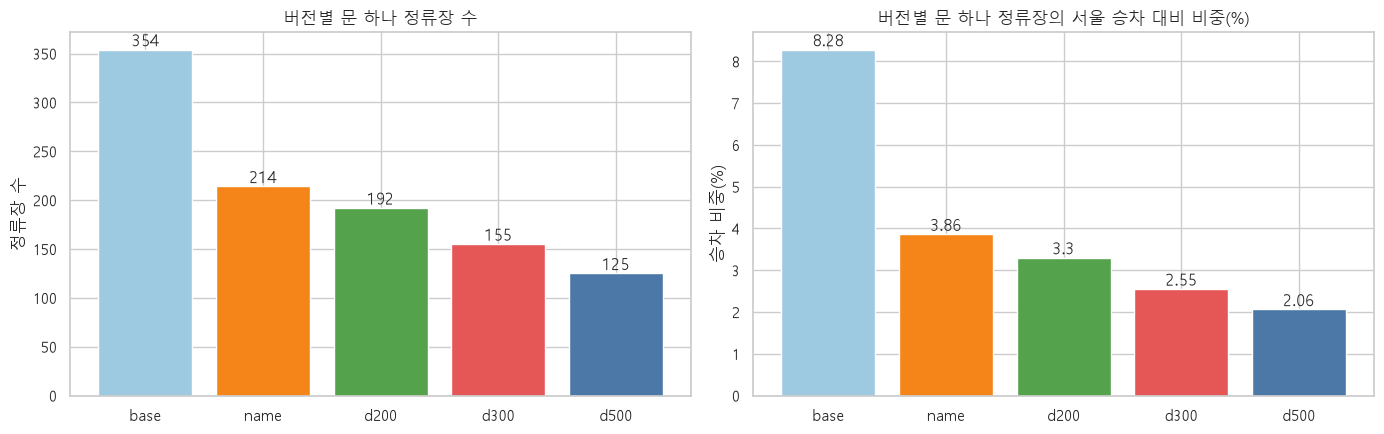

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
colors = ["#9ecae1", "#F58518", "#54A24B", "#E45756", "#4C78A8"]
axes[0].bar(cnt.index, cnt["문하나정류장수"], color=colors)
for i, v in enumerate(cnt["문하나정류장수"]):
    axes[0].text(i, v, f"{v}", ha="center", va="bottom")
axes[0].set_title("버전별 문 하나 정류장 수")
axes[0].set_ylabel("정류장 수")

axes[1].bar(cnt.index, cnt["서울승차대비(%)"], color=colors)
for i, v in enumerate(cnt["서울승차대비(%)"]):
    axes[1].text(i, v, f"{v}", ha="center", va="bottom")
axes[1].set_title("버전별 문 하나 정류장의 서울 승차 대비 비중(%)")
axes[1].set_ylabel("승차 비중(%)")
plt.tight_layout(); plt.show()

## 3. 버전별 상위 20개 정류장

In [10]:
SHOW = ["버스정류장ARS번호", "정류장명", "자치구", "월승차", "멀리가는노선수",
        "1위노선", "쏠림", "가까운역", "가까운역거리m"]


def top20(v):
    d = (stop[stop[v]].sort_values("월승차", ascending=False).head(20)[SHOW]
         .reset_index(drop=True))
    d.index += 1
    return d.round({"쏠림": 3, "가까운역거리m": 0})


for v in VERSIONS:
    print(f"\n{'=' * 100}\n[{v}] 문 하나 정류장 {int(stop[v].sum())}개 중 승차 상위 20개")
    print(top20(v).to_string())


[base] 문 하나 정류장 354개 중 승차 상위 20개
   버스정류장ARS번호              정류장명   자치구     월승차  멀리가는노선수   1위노선     쏠림         가까운역  가까운역거리m
1       21916           신림역4번출구   관악구  172609        0   관악08  0.359           신림     67.0
2       13911          홍제역.3번출구  서대문구  113200        0  서대문09  0.379           홍제     83.0
3       06502               회기역  동대문구  112457        0  동대문01  0.822           회기     56.0
4       21785              낙성대역   관악구  111915        0   관악02  1.000          낙성대    152.0
5       13802             신촌전철역  서대문구  108704        0  서대문03  0.736           신촌     51.0
6       17909          신도림역2번출구   구로구  106937        0  영등포01  0.578          신도림    146.0
7       09567               수유역   강북구   97364        0   도봉02  0.477     수유(강북구청)     85.0
8       09579          미아사거리전철역   강북구   96860        0   강북06  0.740        미아사거리     54.0
9       18503          가산디지털단지역   금천구   94742        0   금천03  1.000      가산디지털단지     69.0
10      09894      미아사거리역.롯데백화점   강북구   90558        0  

In [11]:
# base 상위 20개 중 각 버전에서 몇 개가 살아남나
base20 = set(stop[stop["base"]].sort_values("월승차", ascending=False)
             .head(20)["버스정류장ARS번호"])
surv = pd.DataFrame({
    "base상위20_중_남은수": [len(base20 & set(stop.loc[stop[v], "버스정류장ARS번호"]))
                            for v in VERSIONS],
}, index=VERSIONS)
surv["빠진수"] = 20 - surv["base상위20_중_남은수"]
print(surv.to_string())

for v in ["name", "d200", "d300", "d500"]:
    gone = base20 - set(stop.loc[stop[v], "버스정류장ARS번호"])
    names = stop[stop["버스정류장ARS번호"].isin(gone)].drop_duplicates("버스정류장ARS번호")
    print(f"\n[{v}] base 상위 20개 중 빠진 {len(gone)}개:")
    print(", ".join(names.sort_values("월승차", ascending=False)["정류장명"]))

      base상위20_중_남은수  빠진수
base              20    0
name               2   18
d200               2   18
d300               1   19
d500               1   19

[name] base 상위 20개 중 빠진 18개:
신림역4번출구, 홍제역.3번출구, 회기역, 낙성대역, 신촌전철역, 신도림역2번출구, 수유역, 미아사거리전철역, 가산디지털단지역, 미아사거리역.롯데백화점, 당산역.지하철2호선, 개봉역.림괄아파트, 개봉역, 수유역.강북구청, 양재역.종합복지관, 노량진역, 연신내역6번출구, 이수역

[d200] base 상위 20개 중 빠진 18개:
신림역4번출구, 홍제역.3번출구, 회기역, 낙성대역, 신촌전철역, 신도림역2번출구, 수유역, 미아사거리전철역, 가산디지털단지역, 미아사거리역.롯데백화점, 당산역.지하철2호선, 개봉역.림괄아파트, 개봉역, 수유역.강북구청, 양재역.종합복지관, 노량진역, 연신내역6번출구, 이수역

[d300] base 상위 20개 중 빠진 19개:
신림역4번출구, 홍제역.3번출구, 회기역, 낙성대역, 신촌전철역, 신도림역2번출구, 수유역, 미아사거리전철역, 가산디지털단지역, 미아사거리역.롯데백화점, 당산역.지하철2호선, 개봉역.림괄아파트, 개봉역, 수유역.강북구청, 양재역.종합복지관, 창동역동측(도봉방면), 노량진역, 연신내역6번출구, 이수역

[d500] base 상위 20개 중 빠진 19개:
신림역4번출구, 홍제역.3번출구, 회기역, 낙성대역, 신촌전철역, 신도림역2번출구, 수유역, 미아사거리전철역, 가산디지털단지역, 미아사거리역.롯데백화점, 당산역.지하철2호선, 개봉역.림괄아파트, 개봉역, 수유역.강북구청, 양재역.종합복지관, 창동역동측(도봉방면), 노량진역, 연신내역6번출구, 이수역


## 4. 상명대정문 (ARS 01278)

In [12]:
r = stop[stop["버스정류장ARS번호"] == TARGET].iloc[0]
print(f"정류장명: {r['정류장명']} / 자치구: {r['자치구']}")
print(f"월 승차: {r['월승차']:,} / 멀리 가는 노선 수: {r['멀리가는노선수']} / 쏠림: {r['쏠림']:.3f}")
print(f"가까운 지하철역: {r['가까운역']} ({r['가까운역호선']}) — {r['가까운역거리m']:,.0f} m")
print(f"이름 규칙('○○역') 해당: {bool(r['이름에역'])}")
print()
for v in VERSIONS:
    print(f"  {v:5s}: {'문 하나' if r[v] else '아님'}")

정류장명: 상명대정문 / 자치구: 종로구
월 승차: 61,599 / 멀리 가는 노선 수: 1 / 쏠림: 0.715
가까운 지하철역: 녹번 (3호선) — 1,699 m
이름 규칙('○○역') 해당: False

  base : 문 하나
  name : 문 하나
  d200 : 문 하나
  d300 : 문 하나
  d500 : 문 하나


In [13]:
# 버전별 승차 순위
rk = []
for v in VERSIONS:
    d = stop[stop[v]].sort_values("월승차", ascending=False).reset_index(drop=True)
    pos = d.index[d["버스정류장ARS번호"] == TARGET]
    rk.append({"버전": v, "문하나정류장수": len(d),
               "상명대정문_승차순위": int(pos[0]) + 1 if len(pos) else None,
               "상위(%)": round((int(pos[0]) + 1) / len(d) * 100, 1) if len(pos) else None})
rank_tbl = pd.DataFrame(rk)
print(rank_tbl.to_string(index=False))
print(f"\n→ d300(메인) 기준 상명대정문은 {int(rank_tbl.loc[rank_tbl['버전'] == 'd300', '문하나정류장수'].iloc[0])}개 중 "
      f"{int(rank_tbl.loc[rank_tbl['버전'] == 'd300', '상명대정문_승차순위'].iloc[0])}위")

  버전  문하나정류장수  상명대정문_승차순위  상위(%)
base      354          25    7.1
name      214           5    2.3
d200      192           3    1.6
d300      155           2    1.3
d500      125           2    1.6

→ d300(메인) 기준 상명대정문은 155개 중 2위


In [14]:
# 저장 (3단계에서 사용)
OUT = ["버스정류장ARS번호", "정류장명", "자치구", "월승차", "월하차", "전체노선수",
       "멀리가는노선수", "마을노선수", "쏠림", "1위노선", "마을승차", "마을승차비중",
       "가까운역", "가까운역호선", "가까운역거리m", "이름에역"] + VERSIONS
stop[OUT].to_csv(PROC / "stop_flags_subway.csv", index=False, encoding="utf-8-sig")
print("저장:", (PROC / "stop_flags_subway.csv").resolve())
stop[OUT].head()

저장: C:\study\aix\aix_2\data\processed\stop_flags_subway.csv


,버스정류장ARS번호,정류장명,자치구,월승차,월하차,전체노선수,멀리가는노선수,마을노선수,쏠림,1위노선,마을승차,마을승차비중,가까운역,가까운역호선,가까운역거리m,이름에역,base,name,d200,d300,d500
0,01001,종로2가사거리,종로구,13566,12737,3,2,0,0.507887,470,0.0,0.0,종로3가,1호선,368.058335,False,False,False,False,False,False
1,01002,창경궁.서울대학교병원,종로구,73287,64049,16,16,0,0.155908,272,0.0,0.0,혜화,4호선,582.442602,False,False,False,False,False,False
2,01003,명륜3가.성대입구,종로구,105860,76290,16,16,0,0.146032,272,0.0,0.0,혜화,4호선,311.002391,False,False,False,False,False,False
3,01004,종로2가.삼일교,종로구,17865,19448,5,4,0,0.347719,741,0.0,0.0,종로3가,1호선,424.855903,False,False,False,False,False,False
4,01005,혜화동로터리.여운형활동터,종로구,45545,67337,15,15,0,0.202613,272,0.0,0.0,혜화,4호선,434.527933,False,False,False,False,False,False
